## data processing

In [1]:
import pandas as pd

# Read Excel file
df = pd.read_excel("latest_transactions.xlsx", sheet_name=0, skiprows=8)

In [2]:
#rename column names
df = df.rename(columns={
    '거래 일시': 'Date',
    '적요': 'Remarks',
    '거래 유형': 'Transaction_Type',
    '거래 기관': 'Bank_Name',
    '계좌번호': 'Account_Number',
    '거래 금액': 'Transaction_Amount',
    '거래 후 잔액': 'Balance',
    '메모': 'Memo'
})

# drop columns
df = df.drop(columns=['Unnamed: 0', 'Memo'])

# fill na with 0 and convert to int
df["Account_Number"] = df["Account_Number"].fillna(0).astype(int)

In [3]:
#translate transaction_type column to english
df['Transaction_Type'] = df['Transaction_Type'].replace({
    '체크카드결제': 'Check Card',
    '입금': 'Deposit',
    '출금': 'Withdrawal',
    '프로모션입금': 'Cashback',
    '오픈뱅킹': 'Open Banking',
    '이자입금': 'Interest Deposit',
    'ATM출금': 'ATM Withdrawal',
    'KB국민은행': 'KB Bank',
    'BC카드': 'ATM Deposit'
})

In [4]:
df['Date'] = pd.to_datetime(df['Date'], format='%Y.%m.%d %H:%M:%S')

df['Time'] = df['Date'].dt.time
df['Date'] = df['Date'].dt.date

# Reorder
df = df[['Date', 'Time'] + [col for col in df.columns if col not in ['Date', 'Time']]]

# Save to csv
df.to_csv('transactions.csv', index=False, encoding="utf-8")

In [5]:
import pandas as pd

df = pd.read_csv('transactions.csv')
df.head(10)

,Date,Time,Remarks,Transaction_Type,Bank_Name,Account_Number,Transaction_Amount,Balance
0,2025-12-18,08:40:53,페이브 커피(FAV COFFEE),Check Card,NaN,0,-1500,447672.0
1,2025-12-18,06:12:30,TOSHNIYOZO,Withdrawal,하나은행,74891139488007,-24640,449172.0
2,2025-12-17,19:09:02,스마일마트,Check Card,NaN,0,-10800,473812.0
3,2025-12-17,18:00:00,용현1.4동 주민자,Withdrawal,MG새마을금고,9002192845121,-45000,484612.0
4,2025-12-17,11:12:48,(주)에이션패션 인천 스퀘어원점,Check Card,NaN,0,-109700,529612.0
5,2025-12-17,10:14:40,이마트24 R스퀘어원점,Check Card,NaN,0,-1200,639312.0
6,2025-12-16,20:42:19,MAKHAMMADJ,Withdrawal,하나은행,67291040896107,-26500,640512.0
7,2025-12-16,20:29:50,스마일마트,Check Card,NaN,0,-8400,667012.0
8,2025-12-16,00:02:05,이마트24 인하대점,Check Card,NaN,0,-4300,675412.0
9,2025-12-15,19:53:13,JAMOLOV DILMUROD DILSHOD UGLI,Withdrawal,토스뱅크,100186407011,-350000,679712.0


In [6]:
import pandas as pd

df = pd.read_csv('transactions.csv')
df.to_excel("formatted_transactions.xlsx", index=False)

## IMPORTANT KPIs

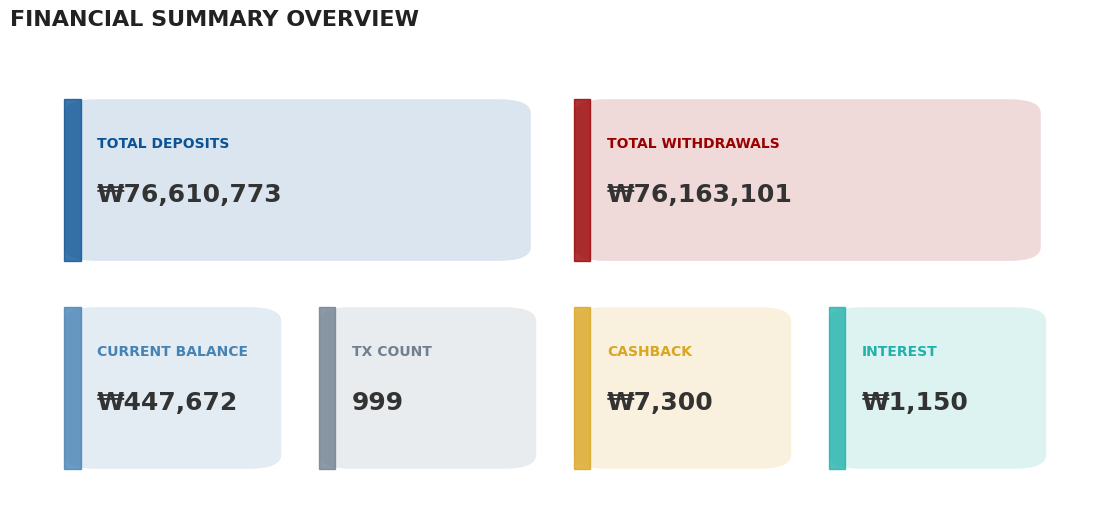

In [7]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Load and calculate (using your logic)
df = pd.read_csv('transactions.csv')
df['Transaction_Amount'] = pd.to_numeric(df['Transaction_Amount'])

# Logic for KPIs
current_balance = df['Balance'].iloc[0] # Usually iloc[0] is the latest in bank exports
total_tx = len(df)
total_deposits = df[df['Transaction_Amount'] > 0]['Transaction_Amount'].sum()
total_withdrawals = abs(df[df['Transaction_Amount'] < 0]['Transaction_Amount'].sum())
total_cashback = df[df['Transaction_Type'] == 'Cashback']['Transaction_Amount'].sum()
total_interest = df[df['Transaction_Type'] == 'Interest Deposit']['Transaction_Amount'].sum()

def draw_kpi_dashboard():
    # Setup Figure (No axes visible)
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.axis('off')

    # Configuration for the two rows
    # [Label, Value, Color, x_pos, y_pos, width, height]
    kpis = [
        # Row 1: Primary Metrics (Larger)
        ["TOTAL DEPOSITS", f"₩{total_deposits:,.0f}", "#0b5394", 5, 55, 43, 35],
        ["TOTAL WITHDRAWALS", f"₩{total_withdrawals:,.0f}", "#990000", 52, 55, 43, 35],
        
        # Row 2: Secondary Metrics (Smaller)
        ["CURRENT BALANCE", f"₩{current_balance:,.0f}", "#4682B4", 5, 10, 20, 35],
        ["TX COUNT", f"{total_tx}", "#708090", 28.5, 10, 20, 35],
        ["CASHBACK", f"₩{total_cashback:,.0f}", "#DAA520", 52, 10, 20, 35],
        ["INTEREST", f"₩{total_interest:,.0f}", "#20B2AA", 75.5, 10, 20, 35],
    ]

    for label, val, color, x, y, w, h in kpis:
        # Create Rounded Rectangle
        # boxstyle="round,pad=-0.04,rounding_size=2" creates the rounded look
        p_bbox = FancyBboxPatch((x, y), w, h,
                                boxstyle="round,pad=0,rounding_size=3",
                                ec="none", fc=color, alpha=0.15)
        ax.add_patch(p_bbox)
        
        # Add a colored side-bar for accent
        ax.add_patch(plt.Rectangle((x, y), 1.5, h, color=color, alpha=0.8))

        # Add Label (Top small text)
        ax.text(x + 3, y + h - 8, label, fontsize=10, fontweight='bold', color=color, va='top')
        
        # Add Value (Large main text)
        # Dynamic font sizing: smaller font if the string is very long
        v_size = 18 if len(val) < 12 else 14
        ax.text(x + 3, y + h - 18, val, fontsize=v_size, fontweight='black', color='#333333', va='top')

    plt.title("FINANCIAL SUMMARY OVERVIEW", fontsize=16, fontweight='bold', pad=20, loc='left', color='#222222')
    
    # Save and show
    if not os.path.exists('visuals'): os.makedirs('visuals')
    plt.savefig('visuals/dashboard_kpis.png', dpi=300, bbox_inches='tight', transparent=False, facecolor='white')
    plt.show()

draw_kpi_dashboard()

=== KPIs ===
Income: 76,610,773 | Expense: 76,163,101 | Net: 447,672


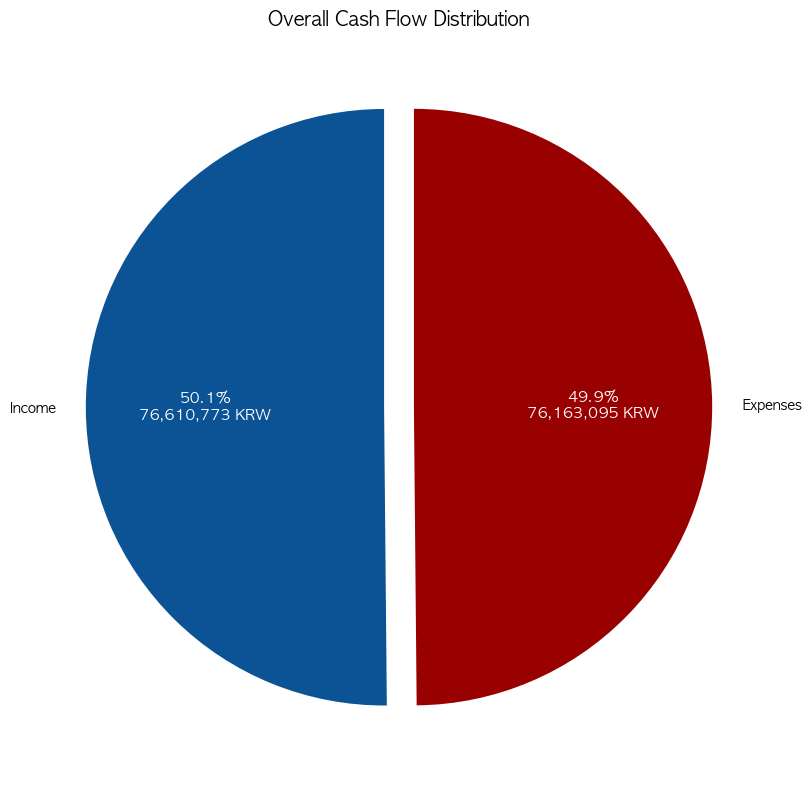

✅ Pie chart saved with Values & White Text.


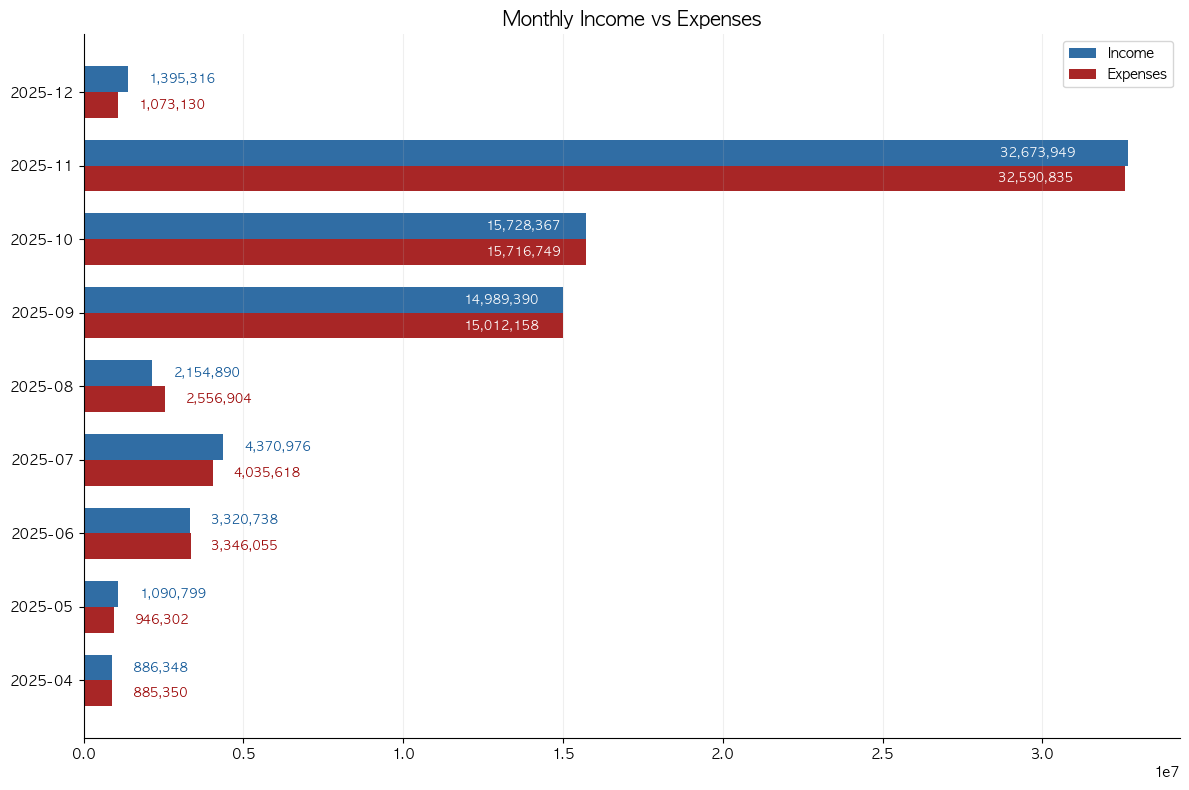

✅ Bar chart saved.


In [8]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

# --- 1. SETUP & DATA PREP ---
os.makedirs('visuals', exist_ok=True)
plt.rcParams['font.family'] = ['AppleGothic', 'Arial Unicode MS'] # Mac Polish
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('transactions.csv')
df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
df['Month'] = df['DateTime'].dt.to_period('M')
df['Transaction_Amount'] = pd.to_numeric(df['Transaction_Amount'])

# Split Data
income = df[df['Transaction_Amount'] > 0].groupby('Month')['Transaction_Amount'].sum()
expense = df[df['Transaction_Amount'] < 0].groupby('Month')['Transaction_Amount'].sum().abs()

# Align Months
all_months = sorted(list(set(income.index) | set(expense.index)))
income = income.reindex(all_months, fill_value=0)
expense = expense.reindex(all_months, fill_value=0)

# KPIs
total_inc, total_exp = income.sum(), expense.sum()
print(f"=== KPIs ===\nIncome: {total_inc:,.0f} | Expense: {total_exp:,.0f} | Net: {total_inc-total_exp:,.0f}")

# --- HELPER: Dynamic Labeling for Bars ---
def annotate_bars(ax, bars, color_text):
    max_val = max(b.get_width() for b in bars)
    for bar in bars:
        w = bar.get_width()
        if w == 0: continue
        inside = w > max_val * 0.15
        x_pos = w * 0.95 if inside else w + (max_val * 0.02)
        
        ax.text(x_pos, bar.get_y() + bar.get_height()/2, f'{w:,.0f}',
                ha='right' if inside else 'left', va='center', 
                color='white' if inside else color_text, 
                fontweight='bold', fontsize=9)

# --- PLOT 1: PIE CHART (UPDATED) ---
fig1, ax1 = plt.subplots(figsize=(10, 8))

sizes = [total_inc, total_exp]
# Custom formatter to show % and Value
def make_autopct(values):
    def my_autopct(pct):
        total = sum(values)
        val = int(round(pct*total/100.0))
        return f'{pct:.1f}%\n{val:,} KRW'
    return my_autopct

# Plotting
wedges, texts, autotexts = ax1.pie(sizes, labels=['Income', 'Expenses'], 
                                   colors=['#0b5394', '#990000'], 
                                   autopct=make_autopct(sizes), # Uses custom formatter
                                   startangle=90, explode=(0.05, 0.05))

ax1.set_title('Overall Cash Flow Distribution', fontsize=14, fontweight='bold')

# Styling the inner text (autotexts)
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(11)

plt.tight_layout()
plt.savefig('visuals/cash_flow_pie_chart.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Pie chart saved with Values & White Text.")


# --- PLOT 2: HORIZONTAL BAR CHART ---
fig2, ax2 = plt.subplots(figsize=(12, 8))
y, h = np.arange(len(all_months)), 0.35

# Plot
b1 = ax2.barh(y + h/2, income, h, label='Income', color='#0b5394', alpha=0.85)
b2 = ax2.barh(y - h/2, expense, h, label='Expenses', color='#990000', alpha=0.85)

# Labels & Polish
annotate_bars(ax2, b1, '#0b5394')
annotate_bars(ax2, b2, '#990000')

ax2.set_title('Monthly Income vs Expenses', fontsize=14, fontweight='bold')
ax2.set_yticks(y); ax2.set_yticklabels([str(m) for m in all_months])
ax2.legend()
ax2.grid(True, alpha=0.2, axis='x')
ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('visuals/monthly_income_expenses_bar.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Bar chart saved.")

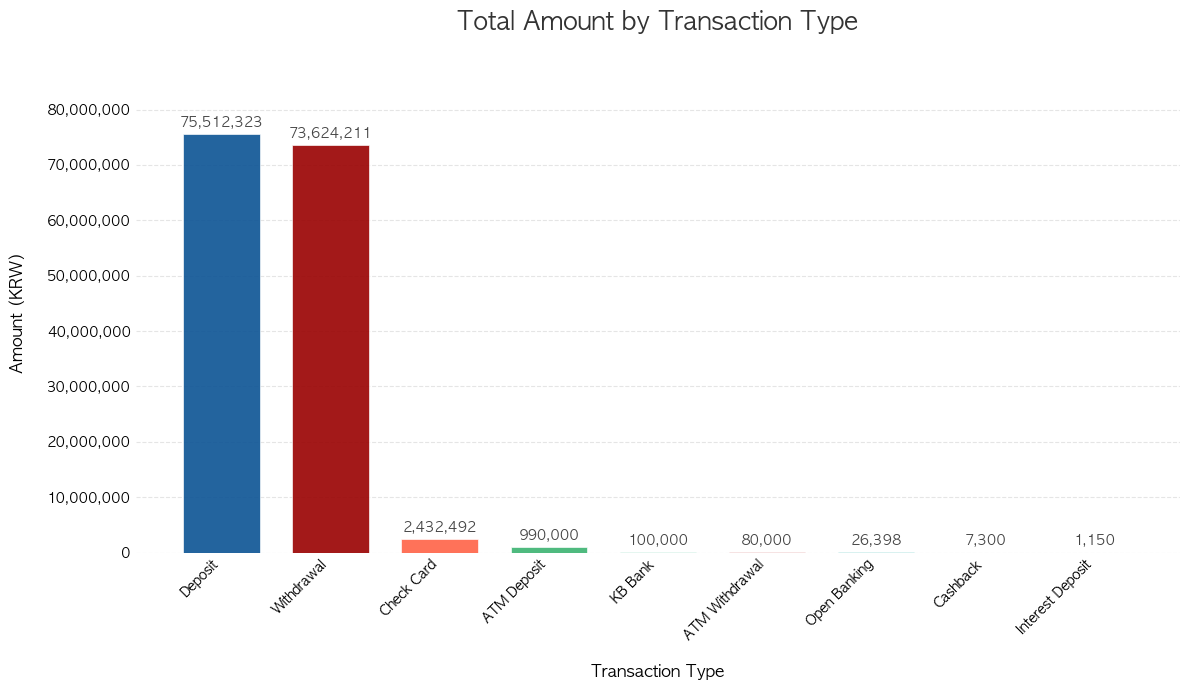

✓ Saved polished vertical chart: total_amount_by_type.png


In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import os

# Load data
df = pd.read_csv('transactions.csv')

# Parse date and convert transaction amount to numeric
df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
df['Transaction_Amount'] = pd.to_numeric(df['Transaction_Amount'])

# Transaction Type Analysis
transaction_stats = df.groupby('Transaction_Type').agg({
    'Transaction_Amount': ['count', 'sum']
}).round(0)

# Flatten column names
transaction_stats.columns = ['Count', 'Total_Amount']

# Define consistent colors
type_colors = {
    'Deposit': '#0b5394',
    'Withdrawal': '#990000',
    'Check Card': '#FF6347',
    'ATM Deposit': '#3CB371',
    'KB Bank': '#66CDAA',
    'ATM Withdrawal': '#CD5C5C',
    'Open Banking': '#20B2AA',
    'Cashback': '#FFD700',
    'Interest Deposit': '#48D1CC'
}

# Sort by absolute amount (Descending for better vertical flow)
amount_sorted = transaction_stats.copy()
amount_sorted['Abs_Amount'] = amount_sorted['Total_Amount'].abs()
amount_sorted = amount_sorted.sort_values('Abs_Amount', ascending=False)

# Map colors
colors_plot = [type_colors.get(t, '#808080') for t in amount_sorted.index]

# Initialize Plot
plt.figure(figsize=(12, 7))
ax = plt.gca()

# Create Vertical Bars
bars = plt.bar(range(len(amount_sorted)), amount_sorted['Abs_Amount'], 
               color=colors_plot, alpha=0.9, edgecolor='white', linewidth=0.5, width=0.7)

# Title and Labels
plt.title('Total Amount by Transaction Type', fontsize=18, fontweight='bold', pad=30, color='#333333')
plt.ylabel('Amount (KRW)', fontsize=12, fontweight='bold', labelpad=15)
plt.xlabel('Transaction Type', fontsize=12, fontweight='bold', labelpad=15)

# Style X-axis (Rotate categories for clarity)
plt.xticks(range(len(amount_sorted)), amount_sorted.index, rotation=45, ha='right', fontsize=10)

# Polish: Remove all borders (spines) and tick marks
for spine in ax.spines.values():
    spine.set_visible(False)
plt.tick_params(axis='both', which='both', length=0)

# Grid - Subtle horizontal lines only
plt.grid(axis='y', alpha=0.2, linestyle='--', color='gray')
ax.set_axisbelow(True)

# Format Y-axis with commas and remove scientific notation
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: format(int(x), ',')))

# Add Value Labels on Top of Bars
max_val = amount_sorted['Abs_Amount'].max()
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + (max_val * 0.01),
             f'{int(height):,}',
             ha='center', va='bottom', fontweight='bold', fontsize=10, color='#444444')

# Prevent extreme values from crossing the top border
plt.ylim(0, max_val * 1.15)

plt.tight_layout()

# Save visual
if not os.path.exists('visuals'): os.makedirs('visuals')
plt.savefig('visuals/total_amount_by_type.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print("✓ Saved polished vertical chart: total_amount_by_type.png")

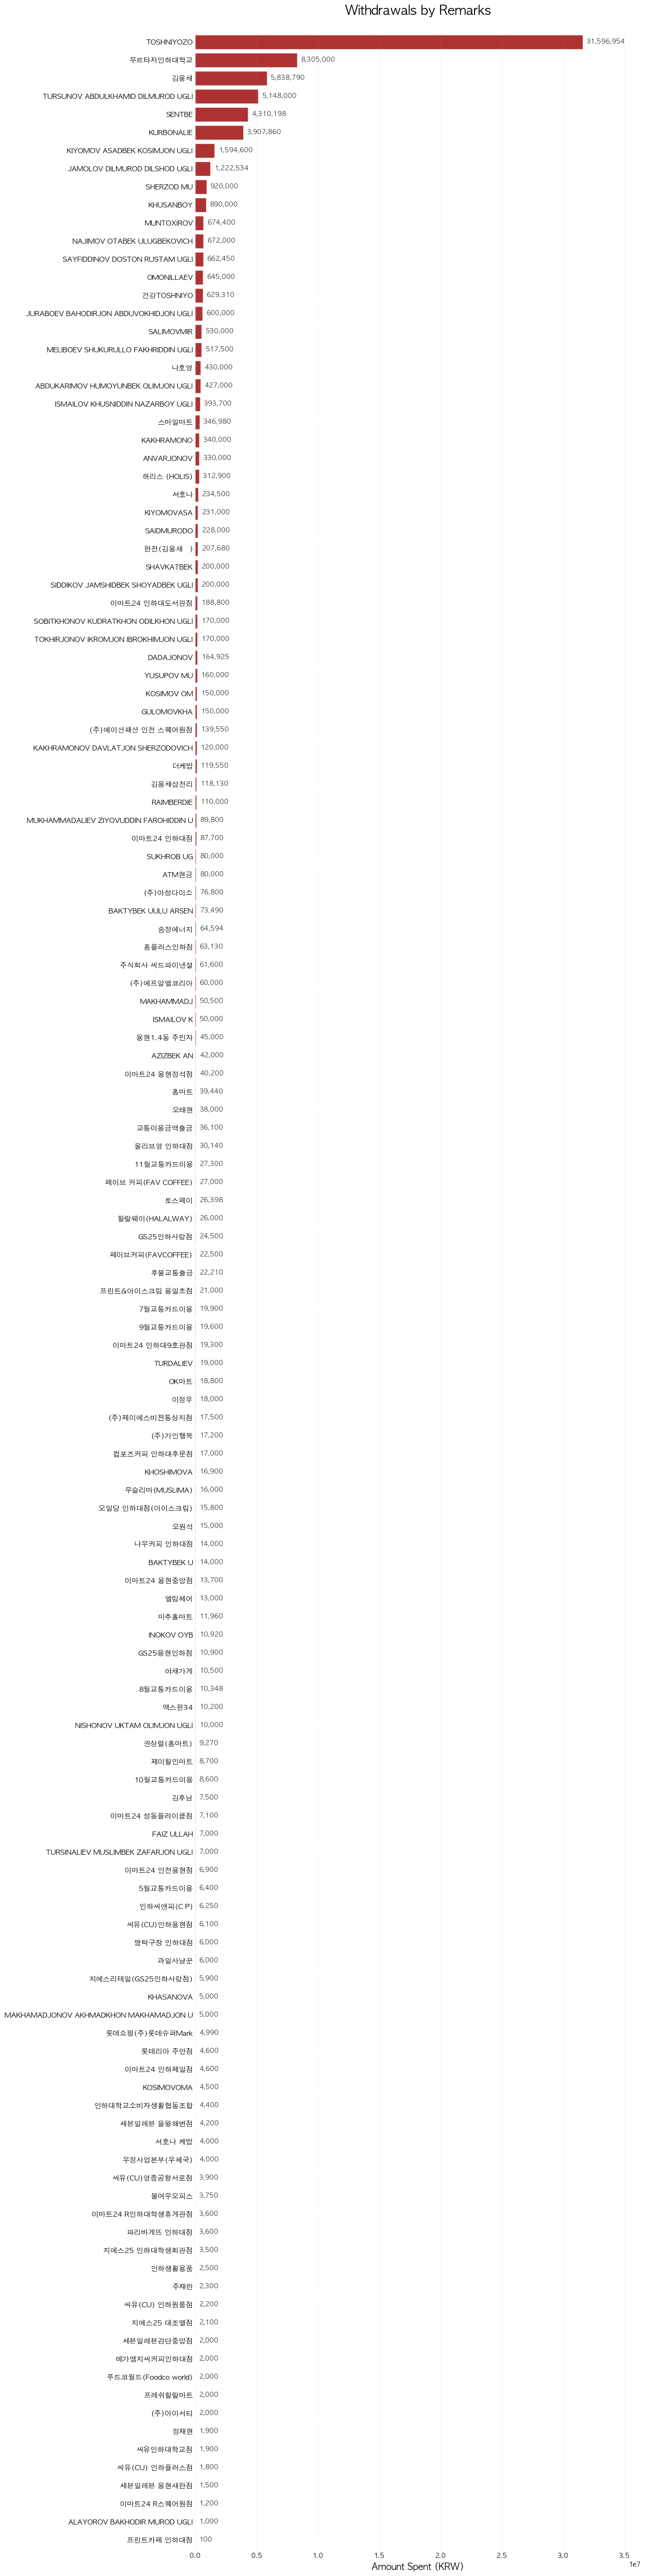

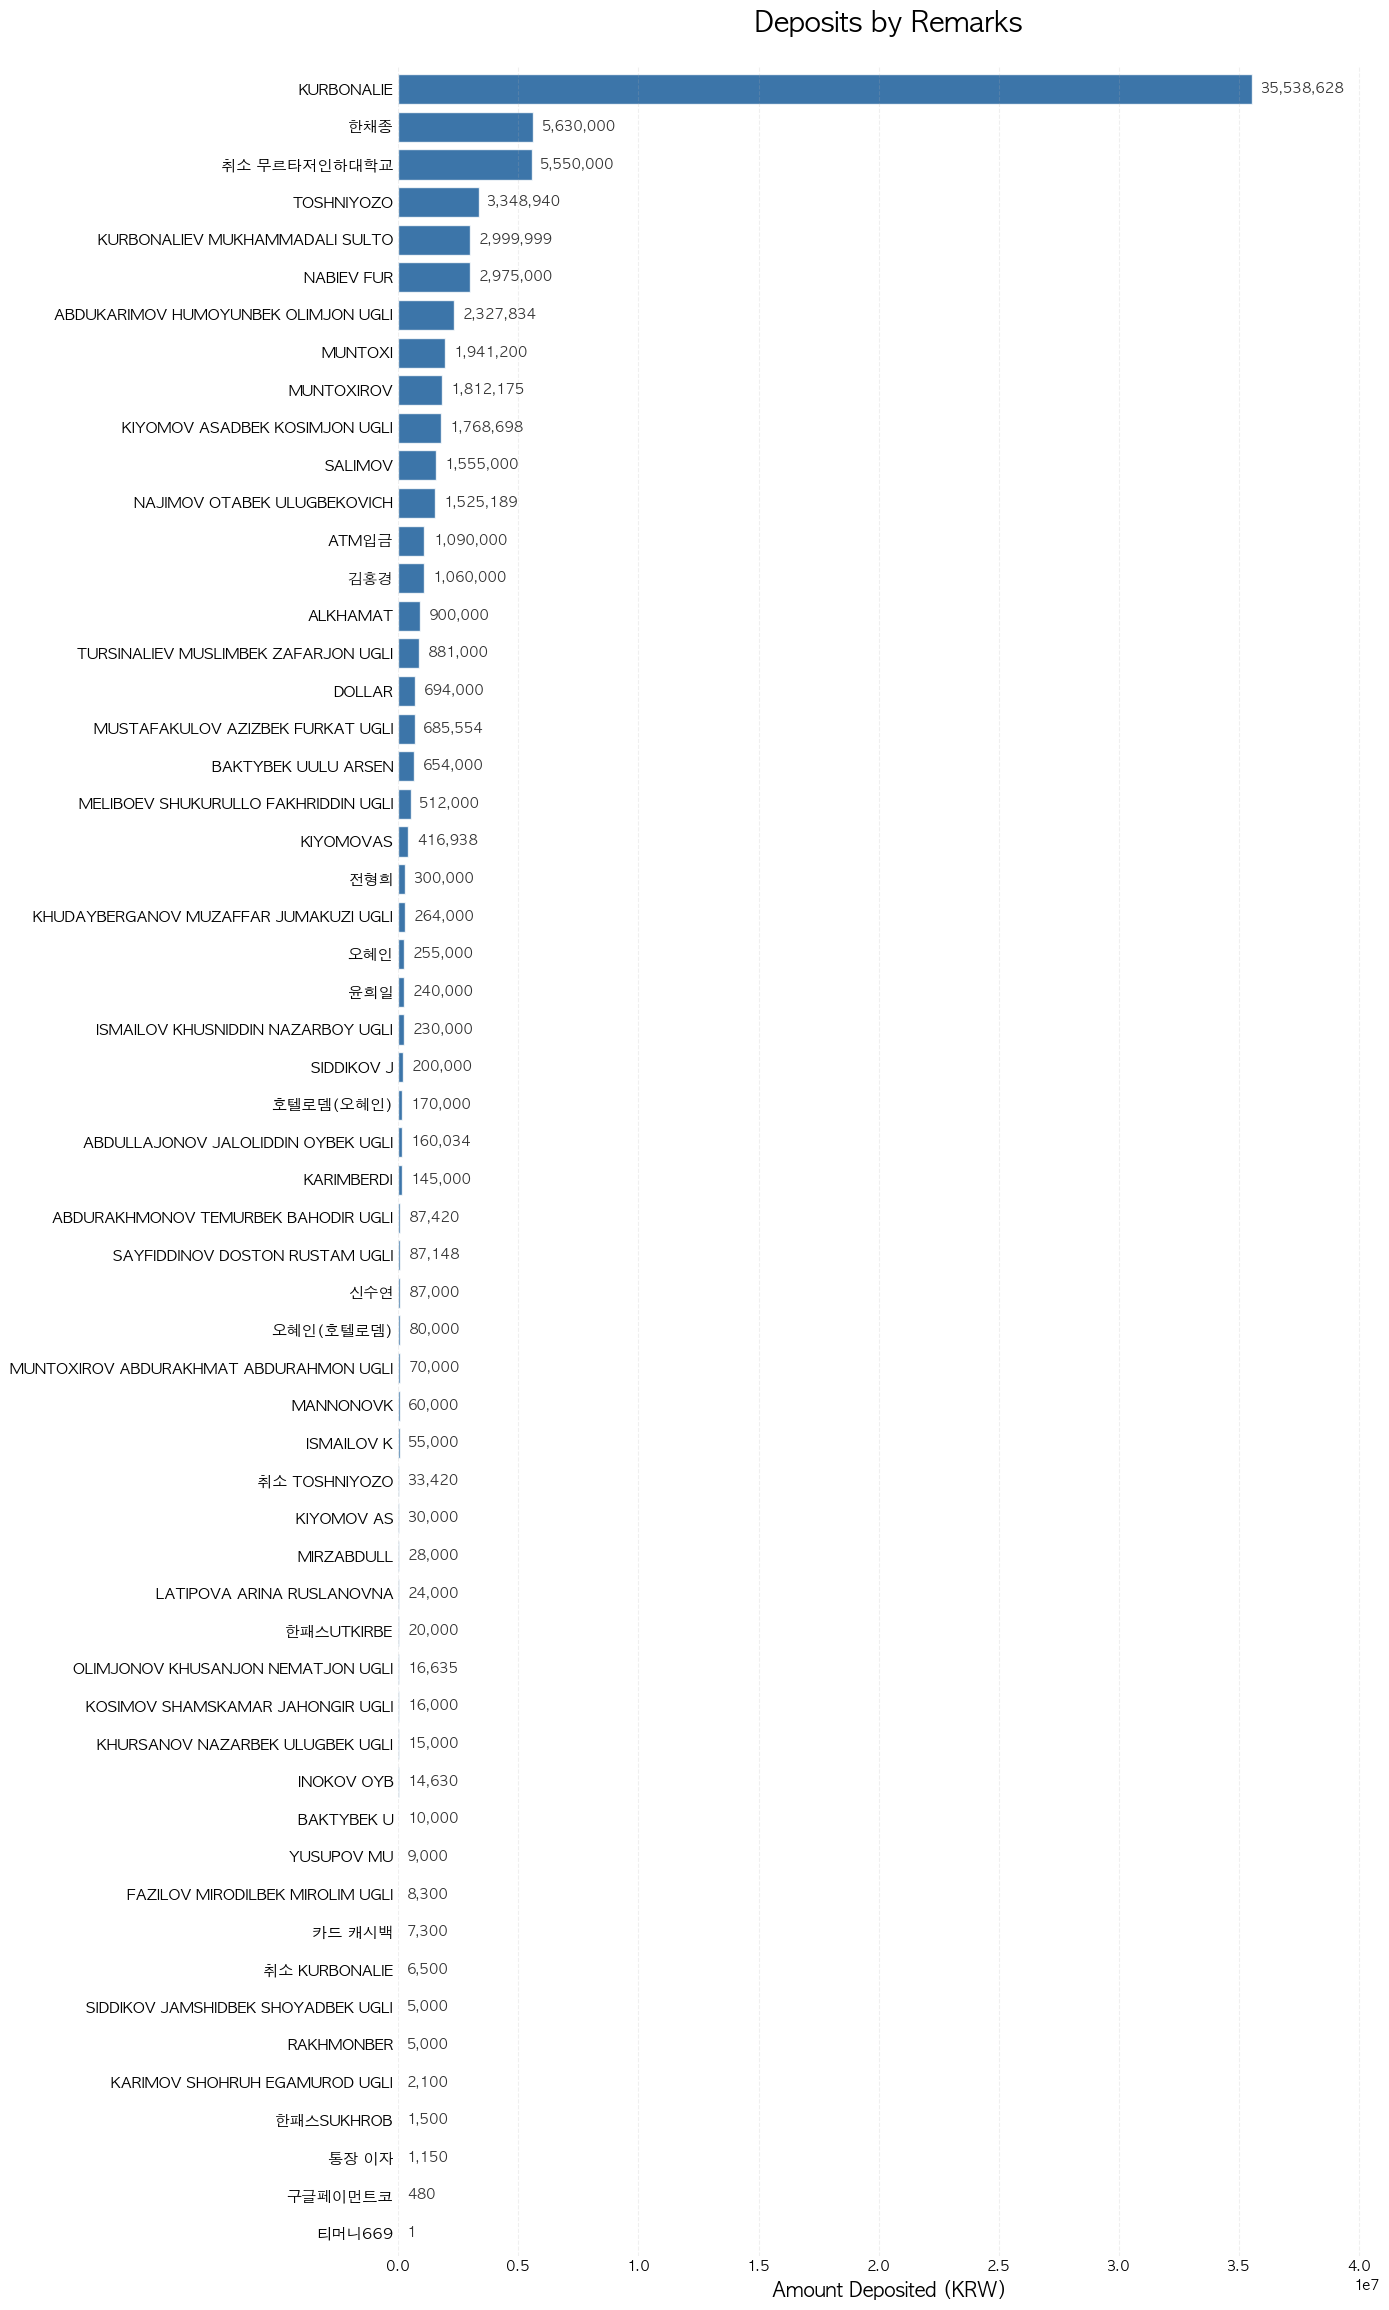

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Create visuals directory if it doesn't exist
if not os.path.exists('visuals'):
    os.makedirs('visuals')

# Korean font setup for macOS
plt.rcParams['font.family'] = ['AppleGothic', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# Read and prepare the data
df = pd.read_csv('transactions.csv')
df['Transaction_Amount'] = pd.to_numeric(df['Transaction_Amount'])

def plot_remarks_analysis(data, is_negative=True):
    """
    Helper function to plot dynamic horizontal bar charts.
    """
    if is_negative:
        # Expenses: Filter negatives and use absolute values
        plot_df = data[data['Transaction_Amount'] < 0].copy()
        plot_df['Value'] = abs(plot_df['Transaction_Amount'])
        title = 'Withdrawals by Remarks'
        color = '#990000'
        filename = 'spending_by_remarks_negative.png'
        xlabel = 'Amount Spent (KRW)'
    else:
        # Deposits: Filter positives
        plot_df = data[data['Transaction_Amount'] >= 0].copy()
        plot_df['Value'] = plot_df['Transaction_Amount']
        title = 'Deposits by Remarks'
        color = '#0b5394'
        filename = 'spending_by_remarks_positive.png'
        xlabel = 'Amount Deposited (KRW)'

    # Group and sort
    series = plot_df.groupby('Remarks')['Value'].sum().sort_values()
    
    # 1. TRUNCATE LABELS: Limit to first 50 characters
    labels = [str(i)[:50] + '...' if len(str(i)) > 50 else str(i) for i in series.index]
    
    # 2. DYNAMIC SCALING: Adjust height based on number of items
    # 0.4 inches per bar is a good rule of thumb for readability
    num_items = len(series)
    dynamic_height = max(6, num_items * 0.4) 
    
    fig, ax = plt.subplots(figsize=(14, dynamic_height))
    
    bars = ax.barh(range(num_items), series.values, color=color, alpha=0.8, edgecolor='white')
    
    # Labels and titles
    ax.set_title(title, fontsize=20, fontweight='bold', pad=25)
    ax.set_xlabel(xlabel, fontsize=14, fontweight='bold')
    ax.set_yticks(range(num_items))
    ax.set_yticklabels(labels, fontsize=11)
    
    # Borderless polish
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis='both', which='both', length=0)
    
    # Add value labels with safe padding
    max_val = series.max() if not series.empty else 1
    for i, v in enumerate(series.values):
        ax.text(v + (max_val * 0.01), i, f'{int(v):,}', 
                va='center', fontweight='bold', fontsize=10, color='#333333')
    
    # Grid and limits
    ax.grid(True, alpha=0.2, axis='x', linestyle='--')
    ax.set_xlim(0, max_val * 1.15) # Buffer for text
    ax.set_ylim(-0.6, num_items - 0.4)
    
    plt.tight_layout()
    plt.savefig(f'visuals/{filename}', dpi=300, bbox_inches='tight')
    plt.show()

# Execute for both types
plot_remarks_analysis(df, is_negative=True)
plot_remarks_analysis(df, is_negative=False)

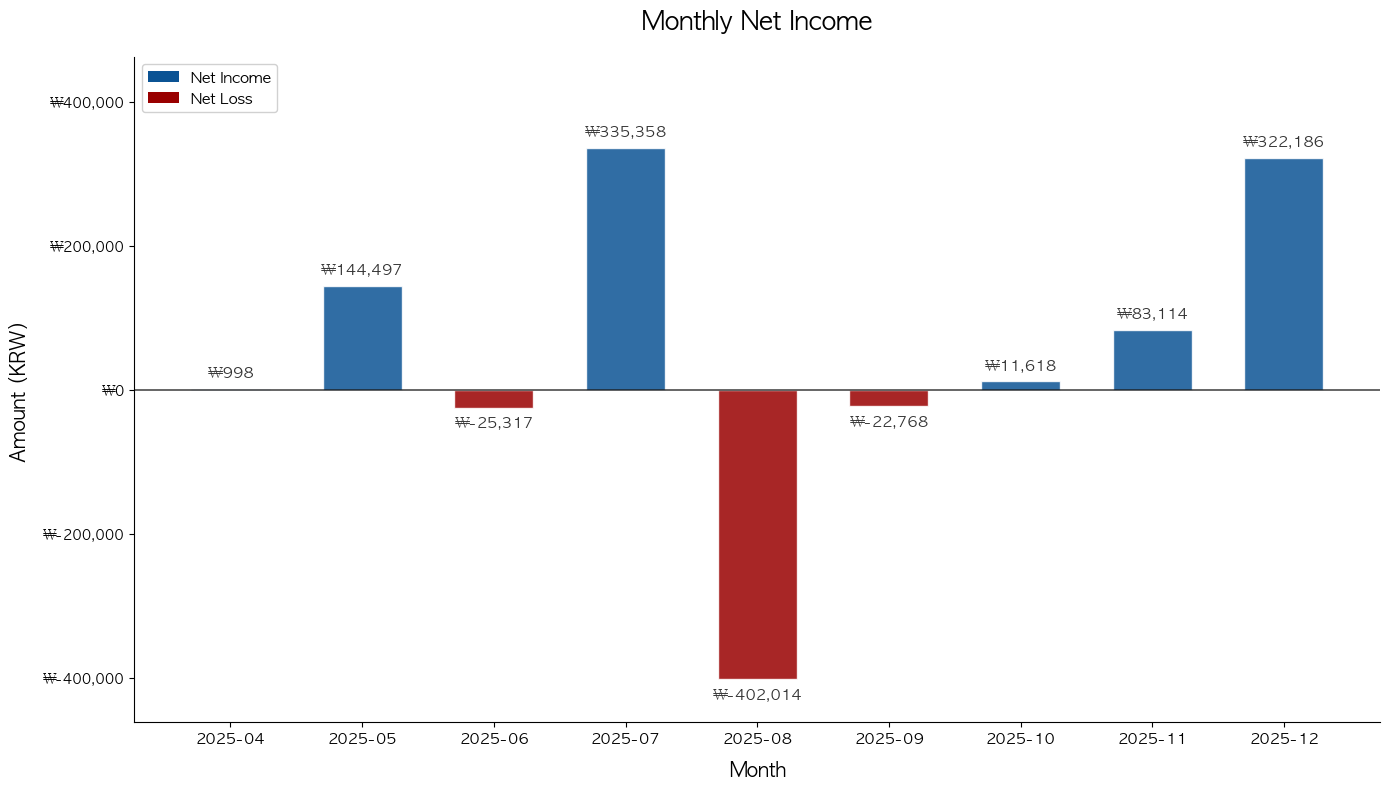

✅ Monthly Net Income chart saved.

Net Income Summary:
  2025-04: ₩998
  2025-05: ₩144,497
  2025-06: ₩-25,317
  2025-07: ₩335,358
  2025-08: ₩-402,014
  2025-09: ₩-22,768
  2025-10: ₩11,618
  2025-11: ₩83,114
  2025-12: ₩322,186


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Read and prepare data
df = pd.read_csv('transactions.csv')
df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
df['Month'] = df['DateTime'].dt.to_period('M')
df['Transaction_Amount'] = pd.to_numeric(df['Transaction_Amount'])

# Calculate monthly income and expenses
income = df[df['Transaction_Amount'] > 0].groupby('Month')['Transaction_Amount'].sum()
expense = df[df['Transaction_Amount'] < 0].groupby('Month')['Transaction_Amount'].sum().abs()

# Align months and calculate net income
all_months = sorted(list(set(income.index) | set(expense.index)))
income = income.reindex(all_months, fill_value=0)
expense = expense.reindex(all_months, fill_value=0)
net_income = income - expense

# Create the bar chart
fig, ax = plt.subplots(figsize=(14, 8))

# Prepare data for plotting
x_pos = np.arange(len(all_months))
colors = ['#0b5394' if val >= 0 else '#990000' for val in net_income]

# Create bars
bars = ax.bar(x_pos, net_income, color=colors, alpha=0.85, width=0.6, edgecolor='white', linewidth=1)

# Add value labels on bars
for i, (bar, val) in enumerate(zip(bars, net_income)):
    height = bar.get_height()
    label_y = height + (max(abs(net_income)) * 0.03) if height >= 0 else height - (max(abs(net_income)) * 0.03)
    va_align = 'bottom' if height >= 0 else 'top'
    ax.text(bar.get_x() + bar.get_width()/2., label_y,
            f'₩{int(val):,}',
            ha='center', va=va_align, fontweight='bold', fontsize=11, color='#333333')

# Styling
ax.set_title('Monthly Net Income', fontsize=18, fontweight='bold', pad=20)
ax.set_ylabel('Amount (KRW)', fontsize=14, fontweight='bold', labelpad=10)
ax.set_xlabel('Month', fontsize=14, fontweight='bold', labelpad=10)
ax.set_xticks(x_pos)
ax.set_xticklabels([str(m) for m in all_months], fontsize=11)

# Add horizontal line at y=0
ax.axhline(y=0, color='black', linestyle='-', linewidth=1.2, alpha=0.7)


# Remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Format y-axis with commas
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'₩{int(x):,}'))

# Add some padding to y-axis limits
y_max = max(abs(net_income.min()), abs(net_income.max())) * 1.15
ax.set_ylim(-y_max, y_max)

# Legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#0b5394', label='Net Income'),
                   Patch(facecolor='#990000', label='Net Loss')]
ax.legend(handles=legend_elements, loc='upper left', fontsize=11, framealpha=0.9)

plt.tight_layout()
plt.savefig('visuals/monthly_net_income.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Monthly Net Income chart saved.")
print(f"\nNet Income Summary:")
for month, value in net_income.items():
    print(f"  {month}: ₩{value:,.0f}")


Index(['Date', 'Time', 'Remarks', 'Transaction_Type', 'Bank_Name',
       'Account_Number', 'Transaction_Amount', 'Balance'],
      dtype='object')


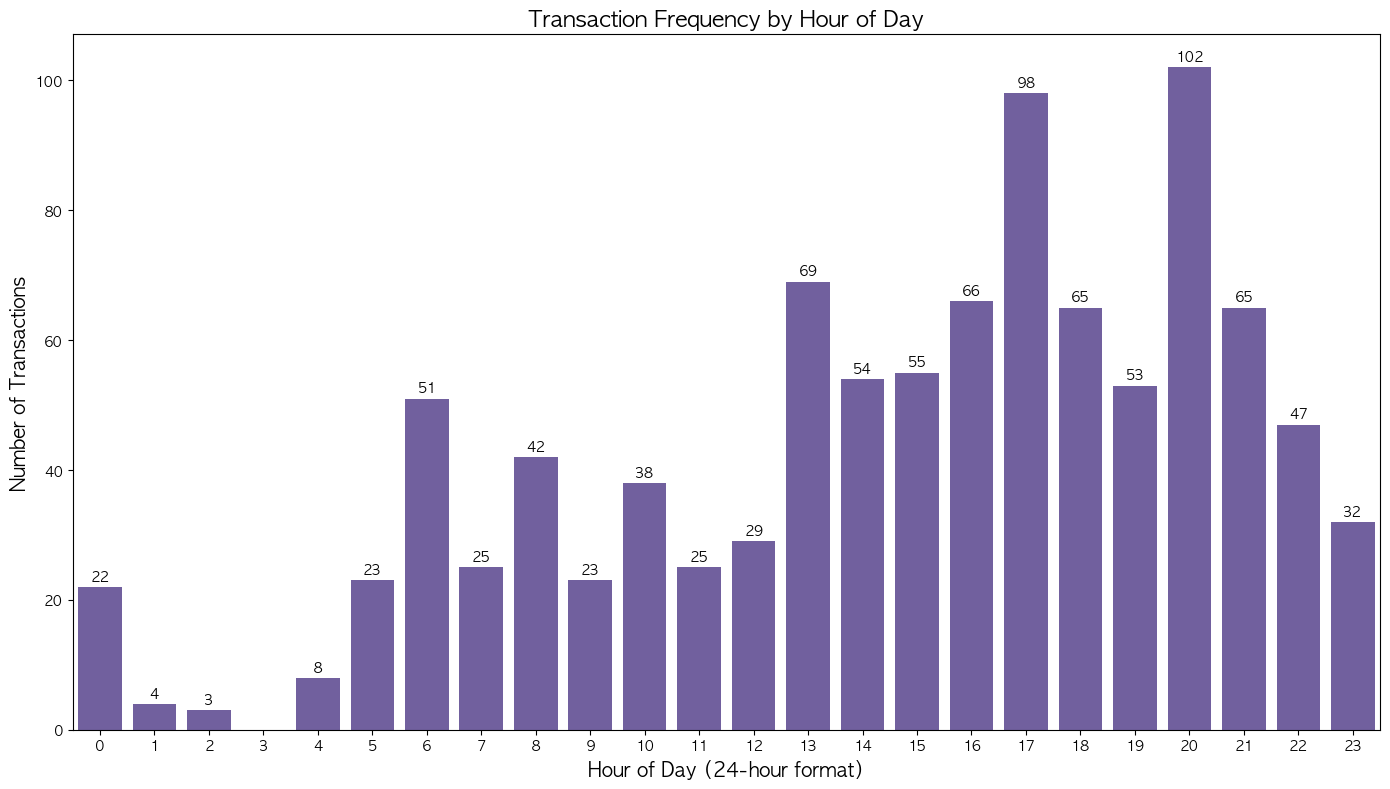

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the data
df = pd.read_csv('transactions.csv')

print(df.columns)

# Combine Date and Time columns, then parse
df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
df['Hour'] = df['DateTime'].dt.hour

# Count transactions per hour
hourly_counts = df['Hour'].value_counts().sort_index()

# Create histogram
plt.figure(figsize=(14, 8))
plt.bar(hourly_counts.index, hourly_counts.values, color='#351c75', alpha=0.7)

plt.title('Transaction Frequency by Hour of Day', fontsize=16, fontweight='bold')
plt.xlabel('Hour of Day (24-hour format)', fontsize=14)
plt.ylabel('Number of Transactions', fontsize=14)

# Set x-axis to show all 24 hours
plt.xticks(range(0, 24))
plt.xlim(-0.5, 23.5)
# plt.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for i, v in hourly_counts.items():
    plt.text(i, v + 0.5, str(v), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('visuals/hourly_transaction_histogram.png', dpi=300, bbox_inches='tight')
plt.show()